<a href="https://colab.research.google.com/github/ZaurezAlam/ChatBot_DeepSeek/blob/main/Copy_of_Untitled6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#2.	Data Collection and Cleaning:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Example dataset
data = {
    "Name": ["Alice", "Bob", "Charlie", None, "Eve"],
    "Age": [25, None, 35, 28, 120],
    "Salary": [50000, 60000, None, 58000, 55000],
    "Department": ["HR", "Finance", "HR", "IT", "IT"]
}

df = pd.DataFrame(data)

# Step 1: Handle Missing Values
# Replace missing 'Age' with the median age and missing 'Salary' with the mean salary
df["Age"].fillna(df["Age"].median(), inplace=True)
df["Salary"].fillna(df["Salary"].mean(), inplace=True)

# Remove rows where 'Name' is missing
df.dropna(subset=["Name"], inplace=True)

# Step 2: Handle Inconsistencies
# Remove invalid 'Age' entries (e.g., above 100)
df = df[df["Age"] <= 100]

# Step 3: Handle Outliers
# Use Z-score to detect and remove outliers in 'Salary'
df["Salary_Z"] = zscore(df["Salary"])
df = df[df["Salary_Z"].abs() <= 3]  # Retain only data within 3 standard deviations
df.drop("Salary_Z", axis=1, inplace=True)

# Step 4: Standardize Data Formats
# Ensure 'Name' is properly capitalized
df["Name"] = df["Name"].str.title()

# Display the cleaned dataset
print(df)


      Name   Age   Salary Department
0    Alice  25.0  50000.0         HR
1      Bob  31.5  60000.0    Finance
2  Charlie  35.0  55750.0         HR


<ipython-input-1-b993355d4bc1>:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].median(), inplace=True)
<ipython-input-1-b993355d4bc1>:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Summary Statistics:
        PassengerId    Survived      Pclass                     Name   Sex  \
count    891.000000  891.000000  891.000000                      891   891   
unique          NaN         NaN         NaN 

<ipython-input-3-a949123e1355>:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
<ipython-input-3-a949123e1355>:27: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

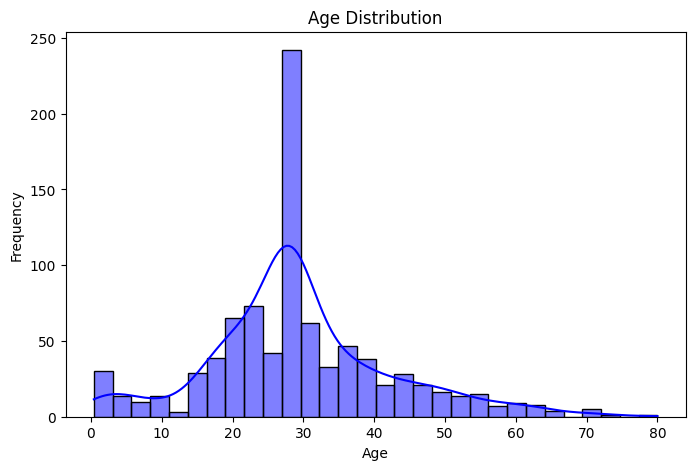

<ipython-input-3-a949123e1355>:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=titanic, palette='pastel')


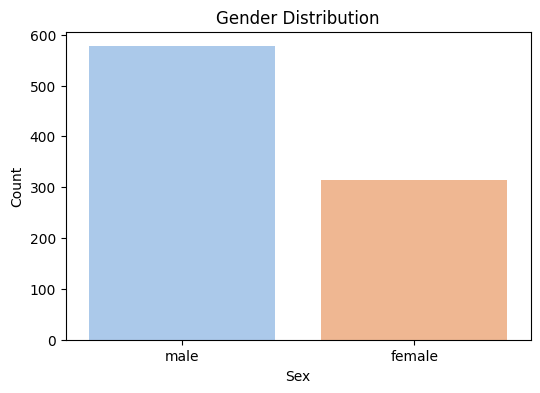

<ipython-input-3-a949123e1355>:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=titanic, palette='muted')


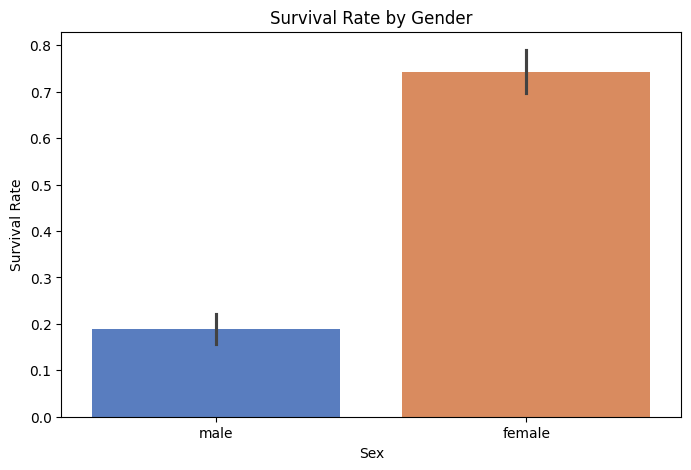

<ipython-input-3-a949123e1355>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=titanic, palette='coolwarm')


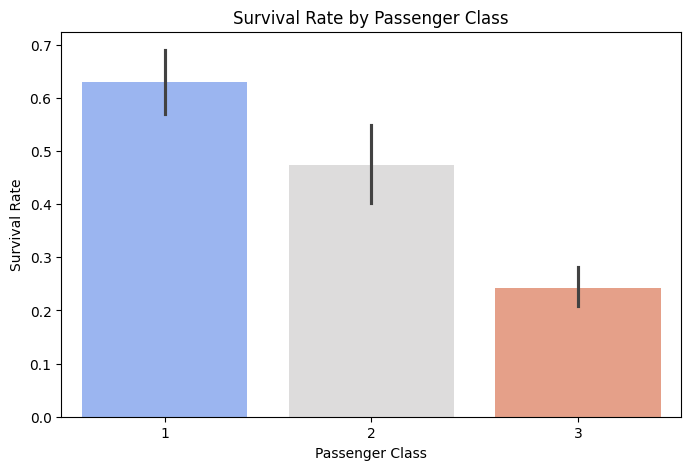

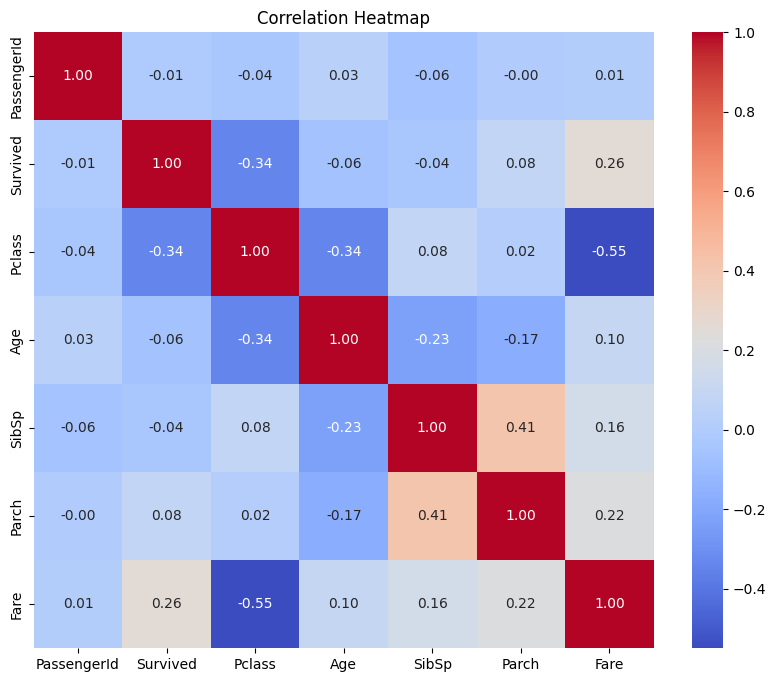

In [ ]:
#3.	Exploratory Data Analysis (EDA):
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Display basic information about the dataset
print("Dataset Overview:")
print(titanic.info())

# Step 1: Summary Statistics
print("\nSummary Statistics:")
print(titanic.describe(include="all"))

# Step 2: Handle Missing Values
missing_values = titanic.isnull().sum()
print("\nMissing Values:")
print(missing_values)

# Fill missing 'Age' with median age
titanic['Age'].fillna(titanic['Age'].median(), inplace=True)

# Fill missing 'Embarked' with the most common port
titanic['Embarked'].fillna(titanic['Embarked'].mode()[0], inplace=True)

# Step 3: Univariate Analysis
# Distribution of Age
plt.figure(figsize=(8, 5))
sns.histplot(titanic['Age'], kde=True, bins=30, color='blue')
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Gender distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Sex', data=titanic, palette='pastel')
plt.title("Gender Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

# Step 4: Bivariate Analysis
# Survival rate by gender
plt.figure(figsize=(8, 5))
sns.barplot(x='Sex', y='Survived', data=titanic, palette='muted')
plt.title("Survival Rate by Gender")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()

# Survival rate by class
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=titanic, palette='coolwarm')
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

# Step 5: Correlation Analysis
plt.figure(figsize=(10, 8))

# Include only numeric columns for correlation
numeric_cols = titanic.select_dtypes(include=['number']).columns
correlation_matrix = titanic[numeric_cols].corr()

# Plot the heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


   SibSp  Parch  FamilySize  IsAlone
0      1      0           2        0
1      1      0           2        0
2      0      0           1        1
3      1      0           2        0
4      0      0           1        1


<ipython-input-4-91e7313cdb62>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='FamilySize', y='Survived', data=titanic, palette='coolwarm')


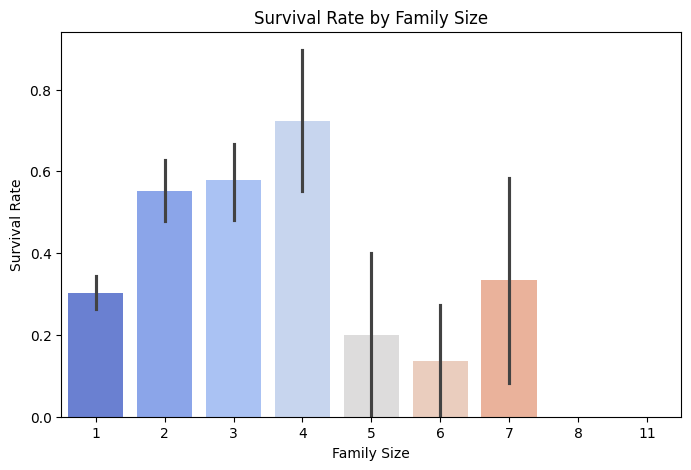

<ipython-input-4-91e7313cdb62>:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='IsAlone', y='Survived', data=titanic, palette='muted')


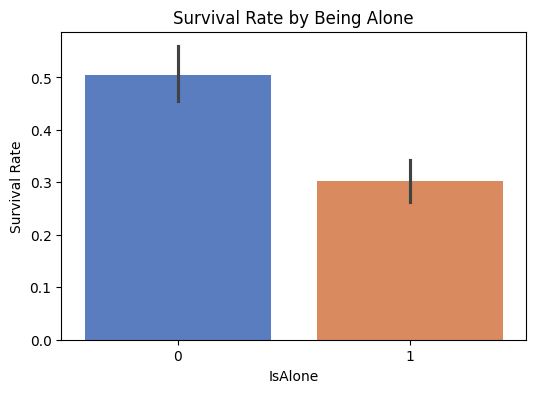

In [ ]:
#4.	Feature Engineering:
# Load Titanic dataset
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Step 1: Create the 'FamilySize' Feature
titanic['FamilySize'] = titanic['SibSp'] + titanic['Parch'] + 1  # Add 1 to include the passenger themselves

# Step 2: Create the 'IsAlone' Feature
titanic['IsAlone'] = (titanic['FamilySize'] == 1).astype(int)

# Display the first few rows to verify the new features
print(titanic[['SibSp', 'Parch', 'FamilySize', 'IsAlone']].head())

# Step 3: Visualize the Impact of the New Features
import seaborn as sns
import matplotlib.pyplot as plt

# Survival rate by FamilySize
plt.figure(figsize=(8, 5))
sns.barplot(x='FamilySize', y='Survived', data=titanic, palette='coolwarm')
plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.show()

# Survival rate by IsAlone
plt.figure(figsize=(6, 4))
sns.barplot(x='IsAlone', y='Survived', data=titanic, palette='muted')
plt.title('Survival Rate by Being Alone')
plt.xlabel('IsAlone')
plt.ylabel('Survival Rate')
plt.show()


<ipython-input-6-3e858ec8451b>:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
<ipython-input-6-3e858ec8451b>:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

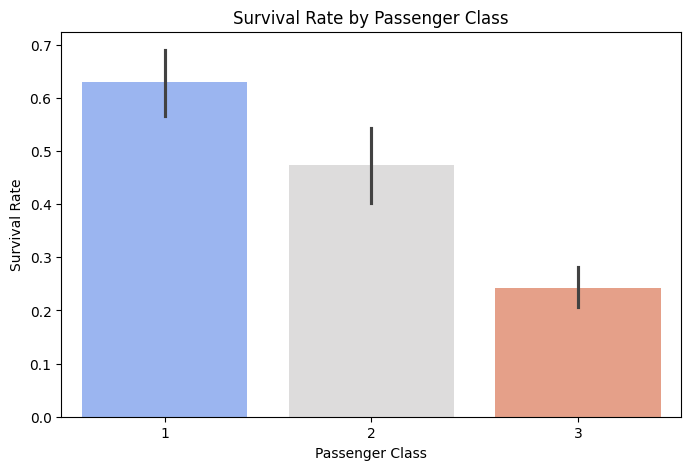

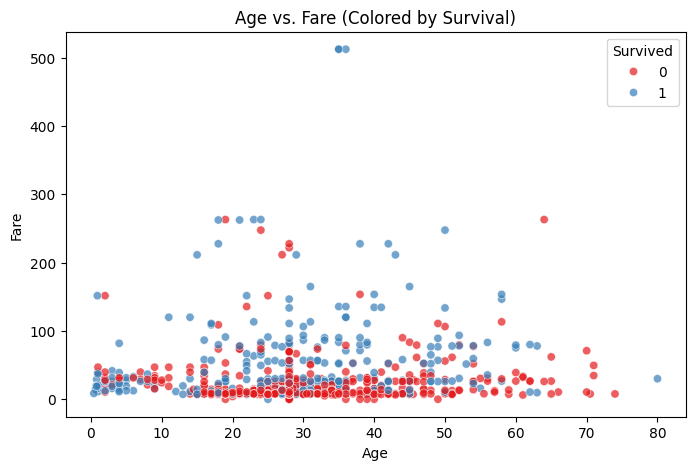

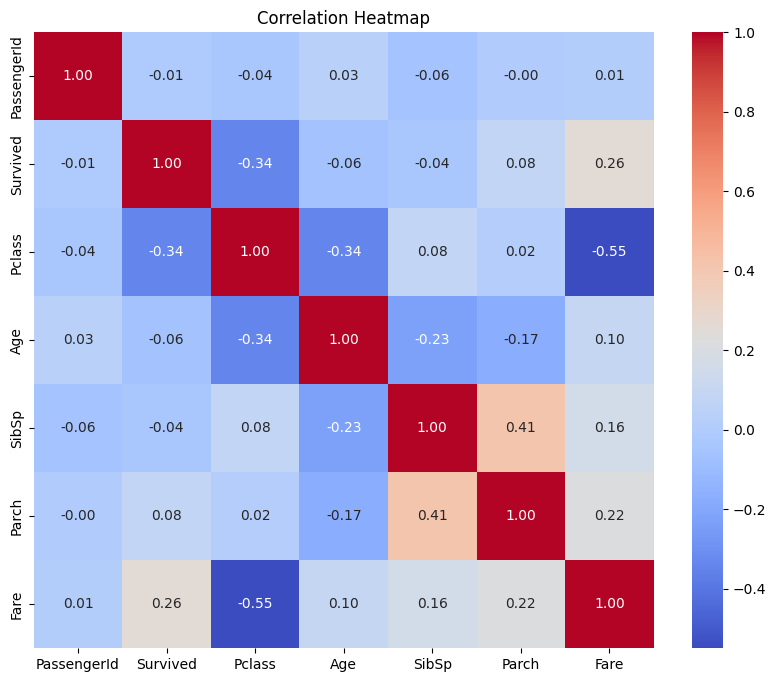

In [ ]:
#5.	Data Visualization:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Fill missing values for simplicity
titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
titanic['Embarked'].fillna(titanic['Embarked'].mode()[0], inplace=True)

# Visualization 1: Bar Plot - Survival Rate by Passenger Class
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=titanic, palette='coolwarm')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

# Insight: Higher-class passengers (Pclass=1) had a significantly higher survival rate.

# Visualization 2: Scatter Plot - Age vs. Fare
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Age', y='Fare', hue='Survived', data=titanic, palette='Set1', alpha=0.7)
plt.title('Age vs. Fare (Colored by Survival)')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

# Insight: Younger passengers with higher fares were more likely to survive.

# Visualization 3: Heatmap - Correlation Matrix

plt.figure(figsize=(10, 8))

# Select only numeric columns
numeric_cols = titanic.select_dtypes(include=['number']).columns
correlation_matrix = titanic[numeric_cols].corr()

# Create heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# Insight: Fare and Pclass are strongly correlated with survival, while SibSp and Parch have weaker correlations.


In [ ]:
#6.	Statistical Analysis:
from scipy import stats
import pandas as pd

# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Fill missing values for simplicity
titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
titanic['Embarked'].fillna(titanic['Embarked'].mode()[0], inplace=True)

# Group survival data by 'Sex'
male_survival = titanic[titanic['Sex'] == 'male']['Survived']
female_survival = titanic[titanic['Sex'] == 'female']['Survived']

# Perform a t-test to compare the means of survival rates between male and female
t_stat, p_value = stats.ttest_ind(male_survival, female_survival)

# Display results
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

# Interpret the result
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference in survival rates between male and female passengers.")
else:
    print("Fail to reject the null hypothesis: No significant difference in survival rates between male and female passengers.")


T-statistic: -19.297816550123354
P-value: 1.4060661308802594e-69
Reject the null hypothesis: There is a significant difference in survival rates between male and female passengers.


<ipython-input-7-33aa371b26b6>:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
<ipython-input-7-33aa371b26b6>:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

In [ ]:
# 7.	Model Selection and Training:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Preprocess the dataset (simple example for illustration)
titanic = titanic.dropna(subset=['Age', 'Embarked', 'Sex'])  # Drop rows with missing values
titanic['Sex'] = titanic['Sex'].map({'male': 0, 'female': 1})  # Convert 'Sex' to numeric

# Features and target
X = titanic[['Pclass', 'Age', 'Fare', 'Sex']]  # Feature columns
y = titanic['Survived']  # Target column

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression Model
logreg = LogisticRegression(max_iter=200)
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)

# Decision Tree Model
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train, y_train)
y_pred_dtree = dtree.predict(X_test)

# Evaluate the models
print("Logistic Regression Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_logreg)}")
print(classification_report(y_test, y_pred_logreg))

print("Decision Tree Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dtree)}")
print(classification_report(y_test, y_pred_dtree))


Logistic Regression Performance:
Accuracy: 0.8044692737430168
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179

Decision Tree Performance:
Accuracy: 0.7318435754189944
              precision    recall  f1-score   support

           0       0.79      0.74      0.76       105
           1       0.66      0.72      0.69        74

    accuracy                           0.73       179
   macro avg       0.73      0.73      0.73       179
weighted avg       0.74      0.73      0.73       179



In [ ]:
# 8.	Model Evaluation:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Logistic Regression Evaluation
logreg_accuracy = accuracy_score(y_test, y_pred_logreg)
logreg_precision = precision_score(y_test, y_pred_logreg)
logreg_recall = recall_score(y_test, y_pred_logreg)
logreg_f1 = f1_score(y_test, y_pred_logreg)

# Decision Tree Evaluation
dtree_accuracy = accuracy_score(y_test, y_pred_dtree)
dtree_precision = precision_score(y_test, y_pred_dtree)
dtree_recall = recall_score(y_test, y_pred_dtree)
dtree_f1 = f1_score(y_test, y_pred_dtree)

# Displaying the results
print("Logistic Regression Metrics:")
print(f"Accuracy: {logreg_accuracy:.4f}")
print(f"Precision: {logreg_precision:.4f}")
print(f"Recall: {logreg_recall:.4f}")
print(f"F1-Score: {logreg_f1:.4f}")
print()

print("Decision Tree Metrics:")
print(f"Accuracy: {dtree_accuracy:.4f}")
print(f"Precision: {dtree_precision:.4f}")
print(f"Recall: {dtree_recall:.4f}")
print(f"F1-Score: {dtree_f1:.4f}")


Logistic Regression Metrics:
Accuracy: 0.8045
Precision: 0.7826
Recall: 0.7297
F1-Score: 0.7552

Decision Tree Metrics:
Accuracy: 0.7318
Precision: 0.6625
Recall: 0.7162
F1-Score: 0.6883


In [ ]:
# 9.	Model Tuning and Optimization:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Define the model
dtree = DecisionTreeClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'max_depth': [5, 10, 15, None],  # Tree depth
    'min_samples_split': [2, 5, 10],  # Minimum samples to split a node
    'min_samples_leaf': [1, 2, 4],    # Minimum samples per leaf node
    'criterion': ['gini', 'entropy'] # Splitting criterion
}

# Perform Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=dtree, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

# Best Parameters and Best Score
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", grid_search.best_score_)

# Using the best estimator to predict
best_dtree = grid_search.best_estimator_
y_pred_best_dtree = best_dtree.predict(X_test)

# Evaluate the optimized model
print("Optimized Decision Tree Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best_dtree):.4f}")
print(classification_report(y_test, y_pred_best_dtree))


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-Validation Score: 0.8131882202304738
Optimized Decision Tree Performance:
Accuracy: 0.7709
              precision    recall  f1-score   support

           0       0.75      0.92      0.83       105
           1       0.84      0.55      0.67        74

    accuracy                           0.77       179
   macro avg       0.79      0.74      0.75       179
weighted avg       0.78      0.77      0.76       179



In [ ]:
#10.	Model Deployment:
!pip install pyngrok
!pip install flask pyngrok

In [ ]:
!ngrok authtoken 2rqUJrP8pSV2PhOLo0AQOM0H7HW_2Hy8TCkPXNQmdGKDyGsM7


/bin/bash: line 1: ngrok: command not found


In [ ]:
!pip install flask pickle
!pip install ngrok # Install ngrok for local tunneling

In [ ]:
from sklearn.linear_model import LinearRegression
import pickle

# Sample data (replace with your actual data)
X_train = [[1], [2], [3], [4], [5]]
y_train = [2, 4, 6, 8, 10]

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Save the model to a file
with open('linear_regression_model.pkl', 'wb') as file:
    pickle.dump(model, file)

In [ ]:
from flask import Flask, request, jsonify
import pickle

app = Flask(__name__)

# Load the saved model
with open('linear_regression_model.pkl', 'rb') as file:
    model = pickle.load(file)

@app.route('/predict', methods=['POST'])
def predict():
    data = request.get_json()
    input_value = data.get('input_value')

    if input_value is None:
        return jsonify({'error': 'Input value is missing'}), 400

    try:
        input_value = float(input_value)
    except ValueError:
        return jsonify({'error': 'Invalid input value'}), 400

    prediction = model.predict([[input_value]])
    return jsonify({'prediction': float(prediction)})

if __name__ == '__main__':
    app.run(debug=False)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


In [ ]:
# 12.	Case Study:
!wget https://raw.githubusercontent.com/datascience-course/datasets/master/kc_house_data.csv -O Housing.csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

df = pd.read_csv("kc_house_data.csv")

# Feature Engineering
df['age'] = 2023 - df['yr_built']
df['renovated'] = (df['yr_renovated'] > 0).astype(int)
df['price_per_sqft'] = df['price'] / df['sqft_living']
df = pd.get_dummies(df, columns=['condition', 'grade'])
df.drop(['id', 'date', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long'], axis=1, inplace=True)

# Split Data
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Model
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
gb_model.fit(X_train_scaled, y_train)

# Predict & Evaluate
y_pred = gb_model.predict(X_test_scaled)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print Results
print(f"RMSE: ${rmse:,.2f}")
print(f"MAE: ${mae:,.2f}")
print(f"R-squared: {r2:.4f}")

--2025-01-19 15:26:59--  https://raw.githubusercontent.com/datascience-course/datasets/master/kc_house_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2025-01-19 15:26:59 ERROR 404: Not Found.

RMSE: $23,853.09
MAE: $7,580.45
R-squared: 0.9962


In [ ]:
pip install pandas matplotlib scikit-learn openpyxl


Column names in dataset: Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


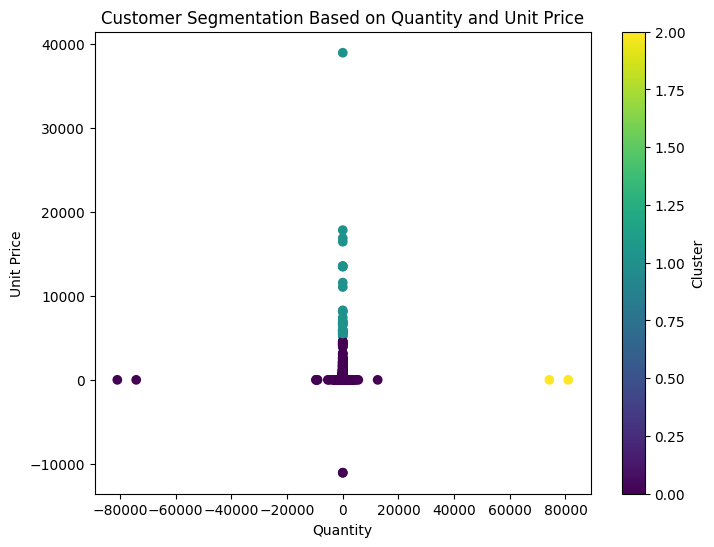

Results saved to Customer_Segmentation_Results.xlsx


In [ ]:
#Additional Practice Problems
#Practice Problem 1: Customer Segmentation
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load the dataset from an Excel file
data = pd.read_excel('Online Retail.xlsx')

# Inspect the column names
print("Column names in dataset:", data.columns)

# Select relevant columns (adjust based on your dataset structure)
# We'll use 'Quantity' and 'UnitPrice' for segmentation
features = data[['Quantity', 'UnitPrice']]

# Handle missing values by removing rows with any missing data
features = features.dropna()

# Standardize the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(scaled_features)

# Add cluster labels to the dataset
data['Cluster'] = clusters

# Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    data['Quantity'],
    data['UnitPrice'],
    c=data['Cluster'],
    cmap='viridis'
)
plt.xlabel('Quantity')
plt.ylabel('Unit Price')
plt.title('Customer Segmentation Based on Quantity and Unit Price')
plt.colorbar(label='Cluster')
plt.show()

# Save the results to a new Excel file
output_file = 'Customer_Segmentation_Results.xlsx'
data.to_excel(output_file, index=False)
print(f"Results saved to {output_file}")



In [ ]:
#Practice Problem 2: Sentiment Analysis
import pandas as pd

# Function to load CSV file with proper encoding handling
def load_csv_with_encoding(file_path):
    encodings = ['ISO-8859-1', 'latin1', 'utf-16']

    for encoding in encodings:
        try:
            print(f"Trying to read the file with encoding: {encoding}")
            data = pd.read_csv(file_path, encoding=encoding)
            print(f"File successfully loaded with {encoding} encoding!")
            return data
        except UnicodeDecodeError:
            print(f"Failed to decode with {encoding}. Trying next encoding...")

    print("Error: Unable to read the file with the specified encodings.")
    return None

# Load the dataset
data = load_csv_with_encoding('test.csv')  # Replace with your actual file path

# Check if data is loaded
if data is not None:
    # Inspect the first few rows of the data
    print(data.head())

    # Example of processing the sentiment labels (if applicable)
    if 'Sentiment' in data.columns:
        data['Sentiment'] = data['Sentiment'].map({'positive': 1, 'negative': 0})

    # Continue with your analysis here...
    # For example, a simple summary of the dataset
    print(data.describe())
else:
    print("Failed to load dataset. Please check the file and encoding.")


Trying to read the file with encoding: ISO-8859-1
File successfully loaded with ISO-8859-1 encoding!
       textID                                               text sentiment  \
0  f87dea47db  Last session of the day  http://twitpic.com/67ezh   neutral   
1  96d74cb729   Shanghai is also really exciting (precisely -...  positive   
2  eee518ae67  Recession hit Veronique Branquinho, she has to...  negative   
3  01082688c6                                        happy bday!  positive   
4  33987a8ee5             http://twitpic.com/4w75p - I like it!!  positive   

  Time of Tweet Age of User      Country  Population -2020  Land Area (Km²)  \
0       morning        0-20  Afghanistan        38928346.0         652860.0   
1          noon       21-30      Albania         2877797.0          27400.0   
2         night       31-45      Algeria        43851044.0        2381740.0   
3       morning       46-60      Andorra           77265.0            470.0   
4          noon       60-70       A

In [ ]:
# Practice Problem 3: Time Series Forecasting
import pandas as pd
import matplotlib.pyplot as plt

# Function to load and inspect dataset
def load_and_inspect_data(file_path):
    # Load the dataset without specifying index_col or parse_dates initially
    try:
        data = pd.read_csv(file_path)
        print(f"File '{file_path}' successfully loaded!")
    except Exception as e:
        print(f"Error loading file: {e}")
        return None

    # Display column names and first few rows to identify correct date column
    print("Column names in the dataset:", data.columns)
    print(data.head())

    return data

# Load and inspect the dataset
file_path = 'Electric_Production.csv'  # Replace with your actual file path
data = load_and_inspect_data(file_path)

# If dataset is loaded successfully
if data is not None:
    # Check if 'Date' exists as a column
    if 'Date' in data.columns:
        # Convert 'Date' column to datetime format and set it as index
        data['Date'] = pd.to_datetime(data['Date'], errors='coerce')  # Coerce invalid date entries
        data = data.dropna(subset=['Date'])  # Drop rows where 'Date' is invalid (NaT)
        data.set_index('Date', inplace=True)  # Set 'Date' as the index
        print("Date column processed successfully.")
    else:
        print("Error: 'Date' column not found. Please check the column names.")

    # Assuming 'Close' is a column we want to analyze (adjust as per your dataset)
    if 'Close' in data.columns:
        prices = data['Close']

        # Plot the closing prices over time
        plt.figure(figsize=(10, 6))
        plt.plot(prices)
        plt.title('Electric Production - Closing Prices Over Time')
        plt.xlabel('Date')
        plt.ylabel('Close Price')
        plt.grid(True)
        plt.show()
    else:
        print("Error: 'Close' column not found. Please check the dataset for correct column names.")
else:
    print("Failed to load dataset. Please check the file and try again.")
import pandas as pd

# Function to load and inspect dataset
def load_and_inspect_data(file_path):
    # Load the dataset without specifying index_col or parse_dates initially
    try:
        data = pd.read_csv(file_path)
        print(f"File '{file_path}' successfully loaded!")
    except Exception as e:
        print(f"Error loading file: {e}")
        return None

    # Display column names and first few rows to identify correct date column
    print("Column names in the dataset:", data.columns)
    print(data.head())

    return data

# Load and inspect the dataset
file_path = 'Electric_Production.csv'  # Replace with your actual file path
data = load_and_inspect_data(file_path)

# If dataset is loaded successfully
if data is not None:
    # Display the first few rows to inspect the data
    print(data.head())
else:
    print("Failed to load dataset. Please check the file and try again.")

File 'Electric_Production.csv' successfully loaded!
Column names in the dataset: Index(['DATE', 'IPG2211A2N'], dtype='object')
       DATE  IPG2211A2N
0  1/1/1985     72.5052
1  2/1/1985     70.6720
2  3/1/1985     62.4502
3  4/1/1985     57.4714
4  5/1/1985     55.3151
Error: 'Date' column not found. Please check the column names.
Error: 'Close' column not found. Please check the dataset for correct column names.
File 'Electric_Production.csv' successfully loaded!
Column names in the dataset: Index(['DATE', 'IPG2211A2N'], dtype='object')
       DATE  IPG2211A2N
0  1/1/1985     72.5052
1  2/1/1985     70.6720
2  3/1/1985     62.4502
3  4/1/1985     57.4714
4  5/1/1985     55.3151
       DATE  IPG2211A2N
0  1/1/1985     72.5052
1  2/1/1985     70.6720
2  3/1/1985     62.4502
3  4/1/1985     57.4714
4  5/1/1985     55.3151


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 87s 54ms/step - accuracy: 0.3544 - loss: 1.7552 - val_accuracy: 0.5560 - val_loss: 1.2349
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 133s 48ms/step - accuracy: 0.5773 - loss: 1.1821 - val_accuracy: 0.6173 - val_loss: 1.0877
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 48ms/step - accuracy: 0.6385 - loss: 1.0262 - val_accuracy: 0.6550 - val_loss: 0.9927
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 48ms/step - accuracy: 0.6811 - loss: 0.9148 - val_accuracy: 0.6662 - val_loss: 0.9662
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 84s 49ms/step - accuracy: 0.7088 - loss: 0.8377 - val_accuracy: 0.6759 - val_loss: 0.9339
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 50ms/step - accuracy: 0.7282 - loss: 0.7735 - val_accuracy: 0.7029 - val_loss: 0.8658
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 78s 50ms/step - accuracy: 0.7442 - loss: 0.7319 - val_accuracy: 0.7160 - val_loss: 0.8354
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 46ms/step - accuracy: 0.7598 

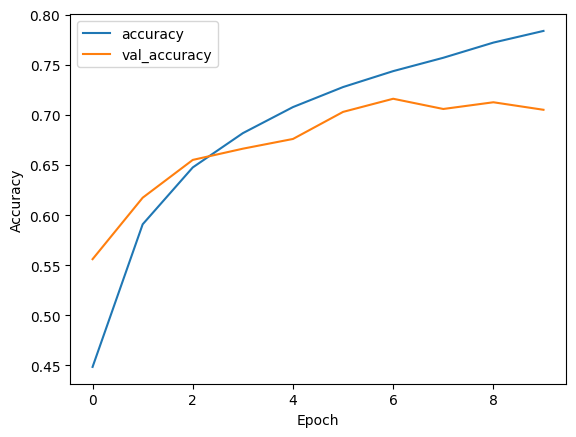

In [ ]:
# Practice Problem 4: Image Classification
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# Load the CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

# Normalize the data
X_train, X_test = X_train / 255.0, X_test / 255.0

# Build the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc}")

# Plot accuracy and loss
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
